# Comparaison des modèles et évaluation finale

Ce notebook **ne ré-entraîne rien** : il relit les runs MLflow de `scripts/train.py` et les modèles de `models/`.

**Protocole.** Sections 1 à 10 sur `val`, où le choix se fait ; section 11, la décision ; `test` n'est ouvert qu'en section 12. Le relire ne l'abîme pas — **seul en tirer une décision l'abîmerait**.

## 1. Chargement des runs et des modèles

In [1]:
# Le projet est installe en mode editable par `uv sync`. Repli au cas ou le
# noyau selectionne ne serait pas celui du projet : on ajoute src/ au chemin.
try:
    import agritech  # noqa: F401
except ModuleNotFoundError:
    import sys
    from pathlib import Path
    _racine = next(p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'pyproject.toml').exists())
    sys.path.insert(0, str(_racine / 'src'))

import json
import time

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
from sklearn.inspection import permutation_importance

from agritech import training
from agritech.config import (BLUE, FEATURES_CATEGORIELLES, FEATURES_FAO,
                             FEATURES_MODELE, FINAL_MODEL_PATH, GREEN,
                             MLFLOW_TRACKING_URI, ORANGE, PRIX_SENSIBILITE,
                             PRIX_TONNE_EUR, PROJECT_ROOT, SPLIT_METADATA_PATH,
                             TARGET)
from agritech.evaluation import (evaluer, latence_prediction,
                                 metriques_economiques, metriques_par_culture,
                                 metriques_prediction, sensibilite_au_prix,
                                 sensibilite_culture)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

MODELES = ['dummy', 'ridge', 'histgbm', 'lightgbm']
COULEURS = {'dummy': '#9aa5b1', 'ridge': BLUE, 'histgbm': GREEN, 'lightgbm': ORANGE}

c:\Users\faiza\Formation_IA\Projet12_mission\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Les modeles sont relus depuis models/ : ce sont exactement ceux enregistres
# dans MLflow, reajustes sur `train` avec les meilleurs hyperparametres.
modeles = {nom: joblib.load(training.chemin_modele(nom, 'modele')) for nom in MODELES}

# `val` seulement : `test` n'est charge qu'en section 12.
train, val = training.charger_partitions()
X_val, y_val = val[FEATURES_MODELE], val[TARGET]

predictions = {nom: m.predict(X_val) for nom, m in modeles.items()}
erreurs = {nom: np.asarray((y_val - p) ** 2) for nom, p in predictions.items()}

versions = json.loads(SPLIT_METADATA_PATH.read_text(encoding='utf-8'))
print(f"data_version  {versions['data_version']}  |  "
      f"split_version {versions['split_version']}")
print(f"train {len(train):,} | val {len(val):,} lignes | "
      f"{len(FEATURES_MODELE)} variables explicatives")
print(f"\nModeles charges : {', '.join(MODELES)}")

data_version  c9547cbd218b  |  split_version ccb2a631078f
train 699,837 | val 149,966 lignes | 13 variables explicatives

Modeles charges : dummy, ridge, histgbm, lightgbm


## 2. Tableau comparatif sur la validation

Trois métriques techniques, puis les mêmes erreurs en euros sous les hypothèses de prix de `config` — des **hypothèses explicites** : aucun jeu de données ne contient de prix.

In [3]:
comparaison = pd.DataFrame([
    {'modele': nom,
     **metriques_prediction(y_val, predictions[nom]),
     **metriques_economiques(y_val, predictions[nom])}
    for nom in MODELES]).set_index('modele').sort_values('rmse')

print(f'Validation — {len(val):,} parcelles | prix retenu {PRIX_TONNE_EUR} EUR/t\n')
comparaison.round(4)

Validation — 149,966 parcelles | prix retenu 200 EUR/t



,rmse,mae,r2,mae_eur_ha,cout_asymetrique_eur_ha,biais_eur_ha
modele,,,,,,
ridge,0.5004,0.3993,0.9132,79.8690,99.9171,0.3234
lightgbm,0.5008,0.3996,0.9131,79.9279,99.9881,0.3129
histgbm,0.5010,0.3998,0.9130,79.9592,100.0356,0.3463
dummy,1.6985,1.3917,-0.0000,278.3418,347.9795,0.2092


## 3. Les écarts sont-ils réels ?

Les trois modèles se tiennent en quelques dix-millièmes de tonne : lire ce classement sans le tester n'aurait pas de sens.

Test **apparié** — erreurs quadratiques comparées sur la même parcelle, ce qui absorbe la corrélation entre modèles. Sa limite : un seul découpage, un seul ajustement ; il ne mesure pas la variabilité d'un réentraînement.

In [4]:
def test_apparie(a, b):
    """z de la difference d'erreur quadratique, observation par observation."""
    d = erreurs[b] - erreurs[a]
    return d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))


reference = comparaison.index[0]
lignes = []
for nom in MODELES:
    if nom == reference:
        continue
    z = test_apparie(reference, nom)
    lignes.append({'modele': nom, 'RMSE': comparaison.loc[nom, 'rmse'],
                   'z contre ' + reference: round(z, 2),
                   'verdict': 'ecart reel' if abs(z) > 2 else 'indiscernable'})

print(f'Reference : {reference} (RMSE {comparaison.loc[reference, "rmse"]:.6f})\n')
pd.DataFrame(lignes).set_index('modele')

Reference : ridge (RMSE 0.500426)



,RMSE,z contre ridge,verdict
modele,,,
dummy,1.698534,292.77,ecart reel
histgbm,0.500987,9.81,ecart reel
lightgbm,0.500795,7.56,ecart reel


## 4. L'optimisation des hyperparamètres a-t-elle servi ?

Cent essais Optuna par modèle, échantillonneur TPE à graine fixe. Une courbe du meilleur RMSE encore descendante à l'essai 100 signalerait un budget insuffisant.

In [5]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

# Les runs enfants portent le RMSE de chaque essai ; seul le parent porte le
# tag `modele`. Les enfants ont bien une colonne `tags.modele`, mais VIDE :
# il faut la retirer avant la fusion, sinon elle masque celle du parent.
tous = mlflow.search_runs(experiment_names=['agritech-rendement'],
                          output_format='pandas')
parents = tous[tous['tags.mlflow.parentRunId'].isna()]
essais = (tous[tous['tags.mlflow.parentRunId'].notna()]
          .drop(columns=['tags.modele'], errors='ignore')
          .merge(parents[['run_id', 'tags.modele']],
                 left_on='tags.mlflow.parentRunId', right_on='run_id',
                 suffixes=('', '_parent')))
essais['essai'] = essais['tags.mlflow.runName'].str.extract(r'(\d+)').astype(int)

assert essais['tags.modele'].notna().all(), 'modele non recupere du parent'
print(f'{len(parents)} runs parents | {len(essais)} essais')
print(essais.groupby('tags.modele')['metrics.val_rmse']
            .agg(['count', 'min', 'max']).round(5).to_string())

4 runs parents | 301 essais
             count      min      max
tags.modele                         
dummy            1  1.69853  1.69853
histgbm        100  0.50099  0.53907
lightgbm       100  0.50079  0.52674
ridge          100  0.50043  0.50362


écrit : optimisation_optuna.png


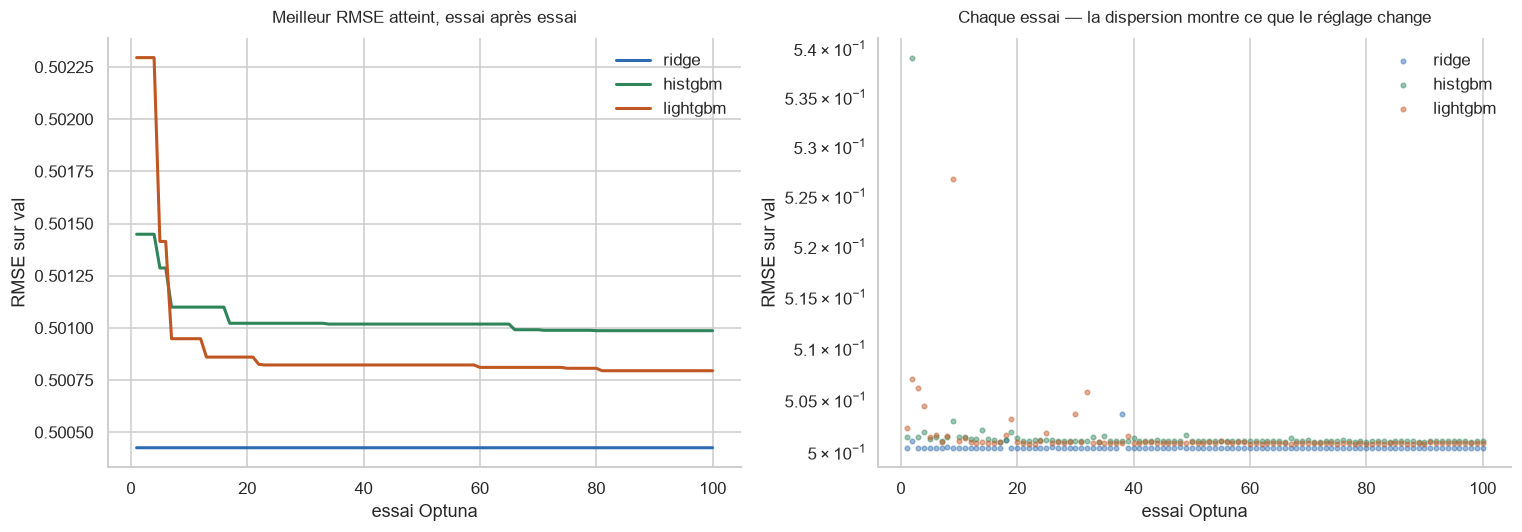

In [6]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(14, 5))

for nom in ['ridge', 'histgbm', 'lightgbm']:
    serie = (essais[essais['tags.modele'] == nom]
             .sort_values('essai')['metrics.val_rmse'])
    # Meilleur RMSE atteint jusqu'a l'essai n : ce que l'optimisation a gagne
    gauche.plot(range(1, len(serie) + 1), serie.cummin(),
                color=COULEURS[nom], lw=2, label=nom)
    droite.scatter(range(1, len(serie) + 1), serie, s=9, alpha=0.45,
                   color=COULEURS[nom], label=nom)

gauche.set_title('Meilleur RMSE atteint, essai après essai', fontsize=11, pad=10)
gauche.set_xlabel("essai Optuna"); gauche.set_ylabel('RMSE sur val')
gauche.legend(frameon=False)

droite.set_title('Chaque essai — la dispersion montre ce que le réglage change',
                 fontsize=11, pad=10)
droite.set_xlabel("essai Optuna"); droite.set_ylabel('RMSE sur val')
droite.set_yscale('log')
droite.legend(frameon=False)
for ax in (gauche, droite):
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)

fig.tight_layout()
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'optimisation_optuna.png'
chemin.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

### 4.1 Quels hyperparamètres ont réellement compté ?

La convergence dit *si* l'optimisation a servi, pas *quel réglage* a compté.

Les études vivaient en mémoire, mais leurs essais sont dans MLflow : on les reconstitue depuis les bornes de `training.ESPACES` — source unique partagée avec l'entraînement, donc sans divergence possible.

In [7]:
from optuna.distributions import IntDistribution
from optuna.trial import create_trial

optuna.logging.set_verbosity(optuna.logging.WARNING)

etudes = {}
for modele in ['ridge', 'histgbm', 'lightgbm']:
    # Les bornes viennent de training.ESPACES, pas d'une copie locale
    distributions = training.distributions_optuna(modele)

    reconstitues = []
    for _, essai in essais[essais['tags.modele'] == modele].iterrows():
        # MLflow stocke les parametres en texte : on retrouve le type d'origine
        parametres = {
            nom: (int(essai[f'params.{nom}']) if isinstance(loi, IntDistribution)
                  else float(essai[f'params.{nom}']))
            for nom, loi in distributions.items()}
        reconstitues.append(create_trial(params=parametres,
                                         distributions=distributions,
                                         value=float(essai['metrics.val_rmse'])))

    etude = optuna.create_study(direction='minimize', study_name=modele)
    etude.add_trials(reconstitues)
    etudes[modele] = etude

# Controle : le meilleur essai reconstitue doit egaler celui qu'a enregistre le
# run parent. Sinon la reconstitution aurait perdu, deforme ou melange un essai.
for modele, etude in etudes.items():
    enregistre = float(parents.loc[parents['tags.modele'] == modele,
                                   'metrics.val_rmse'].iloc[0])
    assert abs(etude.best_value - enregistre) < 1e-9, modele
    print(f'{modele:<10} {len(etude.trials):>3} essais reconstitues | '
          f'meilleur {etude.best_value:.8f} (conforme au run parent)')
    print(f'           {etude.best_params}')

ridge      100 essais reconstitues | meilleur 0.50042586 (conforme au run parent)
           {'alpha': 17.063078568254948}
histgbm    100 essais reconstitues | meilleur 0.50098671 (conforme au run parent)
           {'learning_rate': 0.03574995208591712, 'max_iter': 277, 'max_leaf_nodes': 18, 'min_samples_leaf': 102, 'l2_regularization': 0.0053575811971046956}
lightgbm   100 essais reconstitues | meilleur 0.50079478 (conforme au run parent)
           {'learning_rate': 0.02015294136998677, 'n_estimators': 544, 'num_leaves': 23, 'min_child_samples': 121, 'subsample': 0.6361029680328781, 'colsample_bytree': 0.9051195822629464, 'reg_lambda': 0.0015030397247644577}


écrit : optuna_importances.png


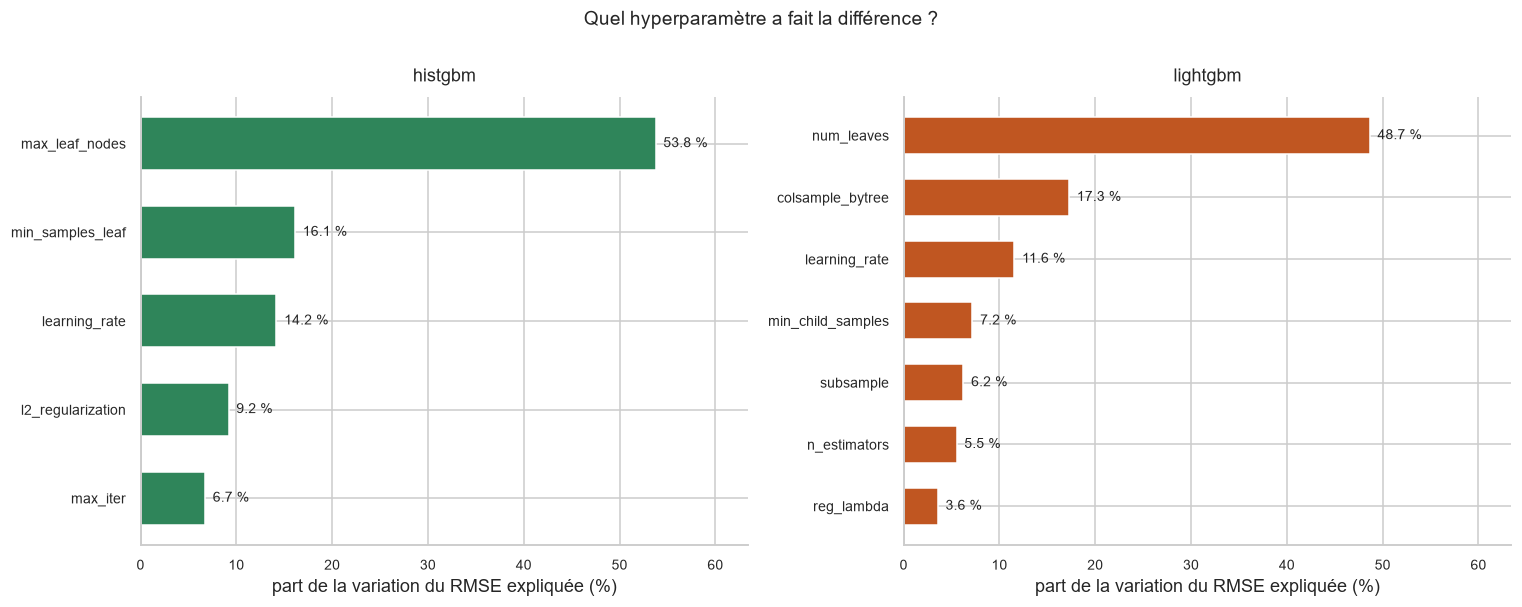

In [8]:
# Part de la variation du RMSE attribuable a chaque hyperparametre.
# Ridge n'en a qu'un, alpha : sa part vaut 100 % par construction, le tracer
# n'apprendrait rien.
importances = {modele: optuna.importance.get_param_importances(etudes[modele])
               for modele in ['histgbm', 'lightgbm']}

# Les deux panneaux partagent l'axe : ce sont deux fois des pourcentages,
# des echelles differentes fausseraient la comparaison visuelle.
plafond = 100 * max(max(parts.values()) for parts in importances.values())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
for ax, (modele, parts) in zip(axes, importances.items()):
    noms = list(parts)[::-1]                      # du moins au plus important
    valeurs = [100 * parts[nom] for nom in noms]
    ax.barh(noms, valeurs, color=COULEURS[modele], height=0.6)
    for y, valeur in enumerate(valeurs):
        ax.text(valeur + plafond * 0.015, y, f'{valeur:.1f} %',
                va='center', fontsize=9)
    ax.set_xlim(0, plafond * 1.18)
    ax.set_xlabel('part de la variation du RMSE expliquée (%)')
    ax.set_title(modele, fontsize=11.5, pad=10)
    ax.tick_params(labelsize=9)
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)

fig.suptitle("Quel hyperparamètre a fait la différence ?", fontsize=12.5, y=1.0)
fig.tight_layout()
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'optuna_importances.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

écrit : optuna_slice.png


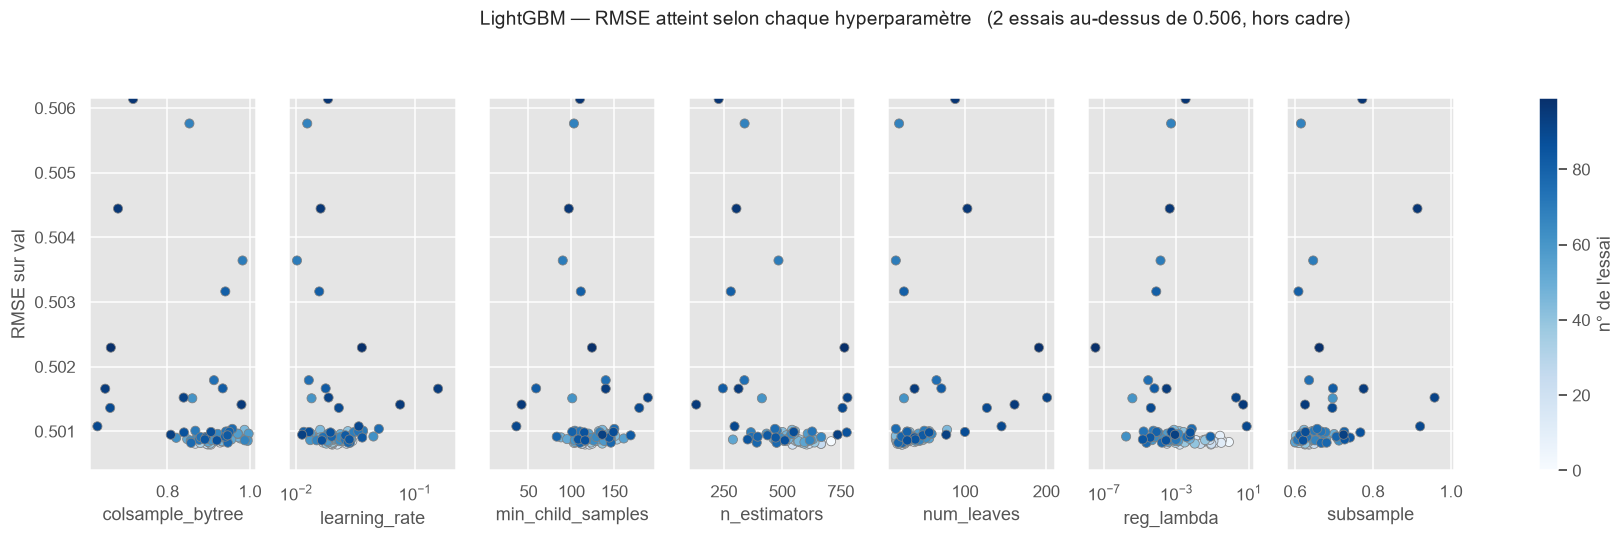


histgbm :
    max_leaf_nodes          53.8 %
    min_samples_leaf        16.1 %
    learning_rate           14.2 %
    l2_regularization        9.2 %
    max_iter                 6.7 %

lightgbm :
    num_leaves              48.7 %
    colsample_bytree        17.3 %
    learning_rate           11.6 %
    min_child_samples        7.2 %
    subsample                6.2 %
    n_estimators             5.5 %
    reg_lambda               3.6 %


In [9]:
# Effet de chaque hyperparametre pris isolement : un nuage par parametre, qui
# montre ou se situent les bons essais dans chaque plage exploree.
import warnings

with warnings.catch_warnings():
    # plot_slice est marque experimental depuis la 2.2 : l'avertissement est
    # attendu et sans portee ici.
    warnings.simplefilter('ignore', optuna.exceptions.ExperimentalWarning)
    from optuna.visualization.matplotlib import plot_slice
    panneaux = plot_slice(etudes['lightgbm'])

# Quelques essais tres mauvais ecraseraient toute la zone utile (0,500-0,506)
# dans le bas du graphe. On recadre, et on annonce combien sortent du cadre.
valeurs_rmse = np.array([essai.value for essai in etudes['lightgbm'].trials])
haut = float(np.quantile(valeurs_rmse, 0.98))
hors_cadre = int((valeurs_rmse > haut).sum())

figure = panneaux[0].figure
for ax in panneaux:
    ax.set_ylim(valeurs_rmse.min() - 4e-4, haut)
    ax.set_ylabel('')
panneaux[0].set_ylabel('RMSE sur val')
for barre in figure.axes[len(panneaux):]:        # la barre de couleur
    barre.set_ylabel("n° de l'essai")

figure.set_size_inches(20, 4.4)
figure.suptitle('LightGBM — RMSE atteint selon chaque hyperparamètre'
                f'   ({hors_cadre} essais au-dessus de {haut:.3f}, hors cadre)',
                fontsize=12.5, y=1.06)
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'optuna_slice.png'
figure.savefig(chemin, dpi=120, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

for modele, parts in importances.items():
    print(f'\n{modele} :')
    for nom, part in parts.items():
        print(f'    {nom:<22} {100 * part:>5.1f} %')

> **Lecture.** La **taille de l'arbre** domine — `num_leaves` 48,7 % (LightGBM), `max_leaf_nodes` 53,8 % (HistGBM) — loin devant le taux d'apprentissage, et les bons essais sont tous du côté des **petits** arbres. Sans structure non linéaire à capter, la capacité ne sert qu'à surapprendre : l'optimisation dépense son budget à rejoindre le comportement que la régression linéaire a d'emblée.

## 5. Prédictions et résidus

écrit : predictions_vs_reel.png


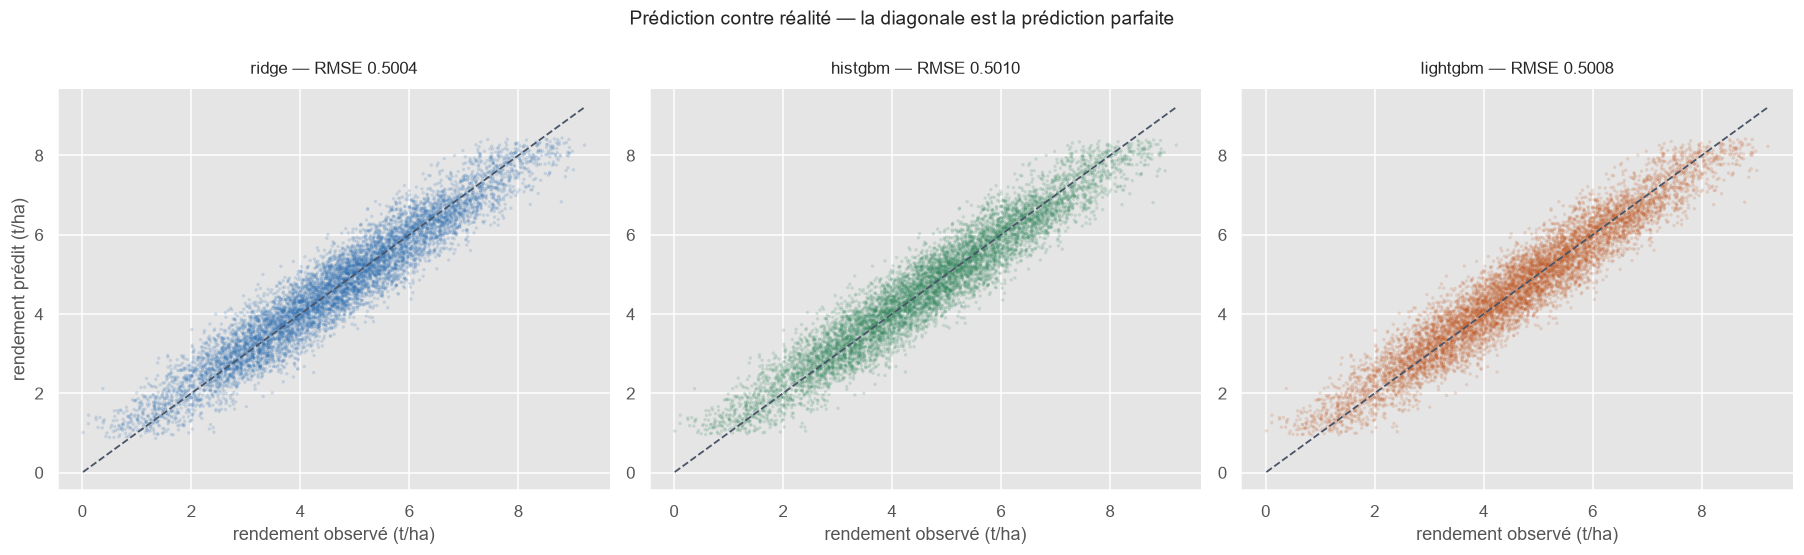

In [10]:
# Un echantillon pour les nuages de points : 150 000 points se superposent
echantillon = val.sample(8_000, random_state=42).index
position = val.index.get_indexer(echantillon)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5))
for ax, nom in zip(axes, ['ridge', 'histgbm', 'lightgbm']):
    vrai = y_val.loc[echantillon]
    predit = predictions[nom][position]
    ax.scatter(vrai, predit, s=5, alpha=0.18, color=COULEURS[nom],
               edgecolors='none')
    bornes = [min(vrai.min(), predit.min()), max(vrai.max(), predit.max())]
    ax.plot(bornes, bornes, color='#4a5568', lw=1.2, ls='--')
    ax.set_title(f'{nom} — RMSE {comparaison.loc[nom, "rmse"]:.4f}',
                 fontsize=11, pad=10)
    ax.set_xlabel('rendement observé (t/ha)')
    ax.set_ylabel('rendement prédit (t/ha)' if nom == 'ridge' else '')
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)

fig.suptitle('Prédiction contre réalité — la diagonale est la prédiction parfaite',
             fontsize=12.5, y=1.0)
fig.tight_layout()
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'predictions_vs_reel.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

écrit : residus.png


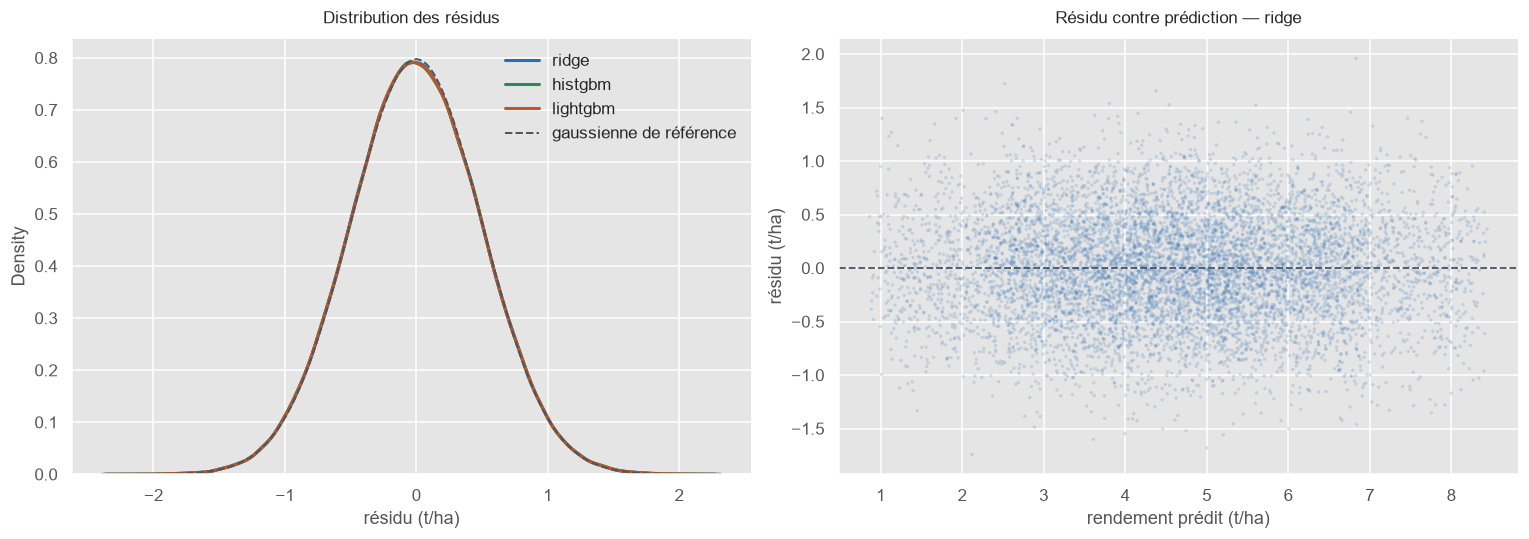

In [11]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(14, 5))

for nom in ['ridge', 'histgbm', 'lightgbm']:
    residus = y_val - predictions[nom]
    sns.kdeplot(residus, ax=gauche, color=COULEURS[nom], lw=2, label=nom)

# Une gaussienne de meme ecart-type : le residu s'en ecarte-t-il ?
residus_ridge = y_val - predictions['ridge']
grille = np.linspace(residus_ridge.min(), residus_ridge.max(), 400)
gauche.plot(grille,
            np.exp(-0.5 * (grille / residus_ridge.std()) ** 2)
            / (residus_ridge.std() * np.sqrt(2 * np.pi)),
            color='#4a5568', lw=1.3, ls='--', label='gaussienne de référence')
gauche.set_title('Distribution des résidus', fontsize=11, pad=10)
gauche.set_xlabel('résidu (t/ha)'); gauche.legend(frameon=False)

# Le residu depend-il du niveau predit ? (heteroscedasticite)
predit_ridge = predictions['ridge'][position]
residu_ech = (y_val.loc[echantillon] - predit_ridge)
droite.scatter(predit_ridge, residu_ech, s=5, alpha=0.18, color=BLUE,
               edgecolors='none')
droite.axhline(0, color='#4a5568', lw=1.2, ls='--')
droite.set_title('Résidu contre prédiction — ridge', fontsize=11, pad=10)
droite.set_xlabel('rendement prédit (t/ha)'); droite.set_ylabel('résidu (t/ha)')

for ax in (gauche, droite):
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)
fig.tight_layout()
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'residus.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

## 6. L'erreur est-elle uniforme entre cultures ?

Une erreur globale faible peut masquer une culture mal traitée. RMSE culture par culture, **avec intervalle de confiance** — sans lui, on lirait du bruit d'échantillonnage.

In [12]:
par_culture = pd.DataFrame({nom: metriques_par_culture(val, predictions[nom])['rmse']
                            for nom in MODELES})

# Intervalle a 95 % du RMSE de chaque culture, par la methode delta
residus_ridge = pd.DataFrame({'Crop': val['Crop'].to_numpy(),
                              'e2': erreurs['ridge']})
bornes = []
for culture, groupe in residus_ridge.groupby('Crop', observed=True):
    rmse = np.sqrt(groupe['e2'].mean())
    et = groupe['e2'].std(ddof=1) / np.sqrt(len(groupe)) / (2 * rmse)
    bornes.append({'Crop': culture, 'n': len(groupe), 'rmse_ridge': rmse,
                   'ic_bas': rmse - 1.96 * et, 'ic_haut': rmse + 1.96 * et})
bornes = pd.DataFrame(bornes).set_index('Crop').sort_values('rmse_ridge')

print('RMSE par culture et par modèle :')
print(par_culture.drop(columns='dummy').round(4).to_string())
print('\nIntervalles de confiance à 95 %, modèle ridge :')
bornes.round(5)

RMSE par culture et par modèle :
          ridge  histgbm  lightgbm
Crop                              
Barley   0.5001   0.5008    0.5004
Cotton   0.5056   0.5062    0.5060
Maize    0.4985   0.4990    0.4989
Rice     0.5036   0.5040    0.5040
Soybean  0.4973   0.4979    0.4976
Wheat    0.4975   0.4980    0.4979

Intervalles de confiance à 95 %, modèle ridge :


,n,rmse_ridge,ic_bas,ic_haut
Crop,,,,
Soybean,24947,0.49725,0.49289,0.50161
Wheat,24996,0.49753,0.49318,0.50188
Maize,25018,0.49845,0.49408,0.50283
Barley,25009,0.50007,0.49567,0.50448
Rice,25013,0.50356,0.49918,0.50795
Cotton,24983,0.50562,0.50113,0.51010


écrit : erreur_par_culture.png


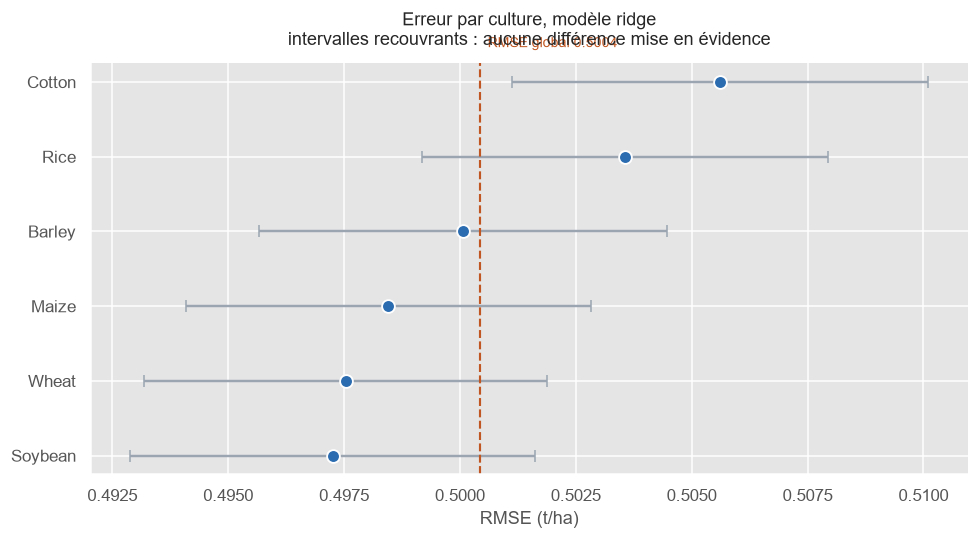

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
position_y = np.arange(len(bornes))
ax.errorbar(bornes['rmse_ridge'], position_y,
            xerr=1.96 * (bornes['ic_haut'] - bornes['rmse_ridge']) / 1.96,
            fmt='none', ecolor='#9aa5b1', elinewidth=1.6, capsize=4, zorder=1)
ax.scatter(bornes['rmse_ridge'], position_y, s=70, color=BLUE,
           zorder=3, edgecolors='white', linewidths=1.2)
ax.axvline(comparaison.loc['ridge', 'rmse'], color=ORANGE, ls='--', lw=1.4)
ax.text(comparaison.loc['ridge', 'rmse'], len(bornes) - 0.4,
        f'  RMSE global {comparaison.loc["ridge", "rmse"]:.4f}',
        color=ORANGE, fontsize=9, va='top')
ax.set_yticks(position_y, bornes.index)
ax.set_xlabel('RMSE (t/ha)')
ax.set_title("Erreur par culture, modèle ridge\n"
             "intervalles recouvrants : aucune différence mise en évidence",
             fontsize=11.5, pad=12)
for cote in ('top', 'right'):
    ax.spines[cote].set_visible(False)
fig.tight_layout()
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'erreur_par_culture.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

## 7. Quelles variables pèsent réellement ?

**SHAP** décompose *le modèle* : la part de chaque variable dans l'écart à la prédiction moyenne. **La permutation** mesure la dégradation du RMSE quand on mélange une colonne — hors échantillon, modèle-agnostique.

**Avertissement.** La matrice de conception a **8 directions dégénérées** (one-hot colinéaires avec la constante, FAO déterminées par `Crop` — §8.6 de la préparation). Quand deux colonnes disent la même chose, les deux méthodes répartissent le crédit **arbitrairement** : d'où le regroupement par variable d'origine.

In [14]:
def variable_source(colonne):
    """Remonte d'une colonne encodee a la variable dont elle est issue.

    `Crop_Maize`, `Crop_Rice`... viennent toutes de `Crop`. Les autres
    colonnes portent deja le nom de leur variable.
    """
    for origine in FEATURES_CATEGORIELLES:
        if colonne.startswith(origine + '_'):
            return origine
    return colonne


def grouper(explication, X, colonnes):
    """Somme les valeurs SHAP des colonnes issues d'une meme variable.

    Renvoie DEUX objets, de valeurs identiques mais de `data` different :
      - `couleur` : la valeur numerique, NaN pour les categorielles. Le
        beeswarm colore par cette valeur — une categorie n'ayant ni haut ni
        bas, NaN la laisse en gris plutot que d'inventer un ordre ;
      - `lecture` : la modalite en clair, pour etiqueter les waterfalls.
    """
    positions = {}
    for rang, colonne in enumerate(colonnes):
        positions.setdefault(variable_source(colonne), []).append(rang)
    noms = list(positions)

    valeurs = np.column_stack([explication.values[:, rangs].sum(axis=1)
                               for rangs in positions.values()])
    couleur = np.column_stack([
        np.full(len(X), np.nan) if nom in FEATURES_CATEGORIELLES
        else X[nom].astype(float).to_numpy() for nom in noms])
    lisible = np.column_stack([
        X[nom].astype(str).to_numpy() if nom in FEATURES_CATEGORIELLES
        else X[nom].astype(float).round(1).astype(str).to_numpy() for nom in noms])

    commun = dict(values=valeurs, base_values=explication.base_values,
                  feature_names=noms)
    return (shap.Explanation(data=couleur, **commun),
            shap.Explanation(data=lisible, **commun))


# SHAP est couteux sur les modeles a base d'arbres : un echantillon suffit,
# les moyennes de contributions sont stables bien avant 150 000 lignes.
ECHANTILLON_SHAP = 3_000
X_shap = val[FEATURES_MODELE].sample(ECHANTILLON_SHAP, random_state=42)

explications, contributions = {}, {}
for nom in ['ridge', 'lightgbm']:
    pretraitement, estimateur = modeles[nom][:-1], modeles[nom][-1]
    Xt = pd.DataFrame(pretraitement.transform(X_shap),
                      columns=pretraitement.get_feature_names_out(),
                      index=X_shap.index)
    debut = time.perf_counter()
    par_colonne = shap.Explainer(estimateur, Xt)(Xt)

    # REGROUPEMENT IMMEDIAT, avant toute lecture : une valeur SHAP sur une
    # colonne one-hot prise isolement ne veut rien dire.
    explications[nom] = grouper(par_colonne, X_shap, Xt.columns)
    contributions[nom] = pd.Series(
        np.abs(explications[nom][0].values).mean(axis=0),
        index=explications[nom][0].feature_names)
    print(f'{nom:<10} {time.perf_counter() - debut:>5.1f} s | '
          f'{Xt.shape[1]} colonnes -> {len(contributions[nom])} variables')

shap_variables = pd.DataFrame(contributions).sort_values('ridge', ascending=False)
assert len(shap_variables) == len(FEATURES_MODELE), 'regroupement incomplet'

# Controle : les contributions groupees reconstituent-elles la prediction ?
couleur_ridge, lecture_ridge = explications['ridge']
reconstruit = couleur_ridge.base_values + couleur_ridge.values.sum(axis=1)
ecart = np.abs(reconstruit - modeles['ridge'].predict(X_shap)).max()
print(f'\nEcart max entre somme des contributions et prediction : {ecart:.2e}')
print(f'\nContribution SHAP moyenne, par VARIABLE ({len(shap_variables)} lignes) :')
shap_variables.round(5)

Background dataset has 3000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=3000 when initializing the masker.
Background dataset has 3000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=3000 when initializing the masker.


ridge        0.1 s | 28 colonnes -> 13 variables


 98%|===================| 2943/3000 [00:25<00:00]        

lightgbm    25.2 s | 28 colonnes -> 13 variables

Ecart max entre somme des contributions et prediction : 1.78e-15

Contribution SHAP moyenne, par VARIABLE (13 lignes) :


,ridge,lightgbm
Rainfall_mm,1.09819,1.05208
Fertilizer_Used,0.75006,0.75080
Irrigation_Used,0.60067,0.48130
Temperature_Celsius,0.12543,0.12411
Crop,0.00125,0.00097
Region,0.00121,0.00086
Soil_Type,0.00111,0.00095
crop_productivity_index,0.00064,0.00052
crop_in_fao_reference,0.00053,0.00017
crop_yield_geo_cv,0.00035,0.00023


### 7.1 Dépendance globale

Le **bar plot** classe par contribution moyenne absolue ; le **beeswarm** montre la distribution complète, colorée par la valeur de la variable — ce qui révèle le *sens* de l'effet.

Les catégorielles restent en **gris** : les colorer inventerait un ordre entre `Chalky` et `Clay`.

écrit : shap_bar.png


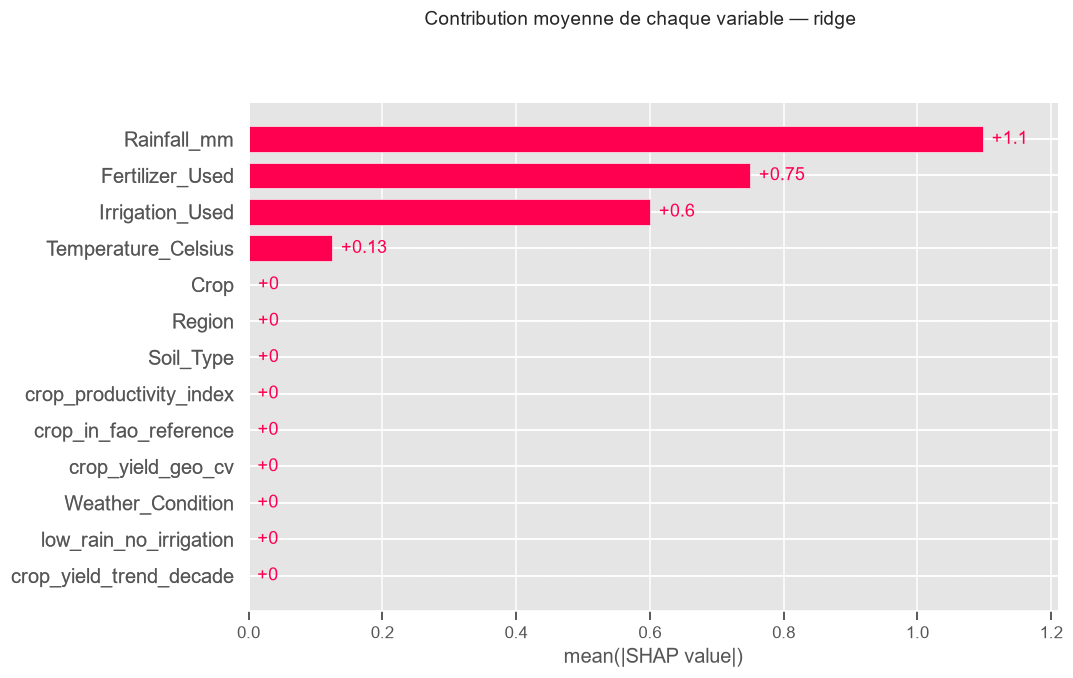

In [15]:
couleur_ridge, _ = explications['ridge']

plt.figure()
shap.plots.bar(couleur_ridge, max_display=len(FEATURES_MODELE), show=False)
figure = plt.gcf()
figure.set_size_inches(9.5, 6)
figure.suptitle('Contribution moyenne de chaque variable — ridge',
                fontsize=12.5, y=1.02)
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'shap_bar.png'
figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

c:\Users\faiza\Formation_IA\Projet12_mission\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


écrit : shap_beeswarm.png


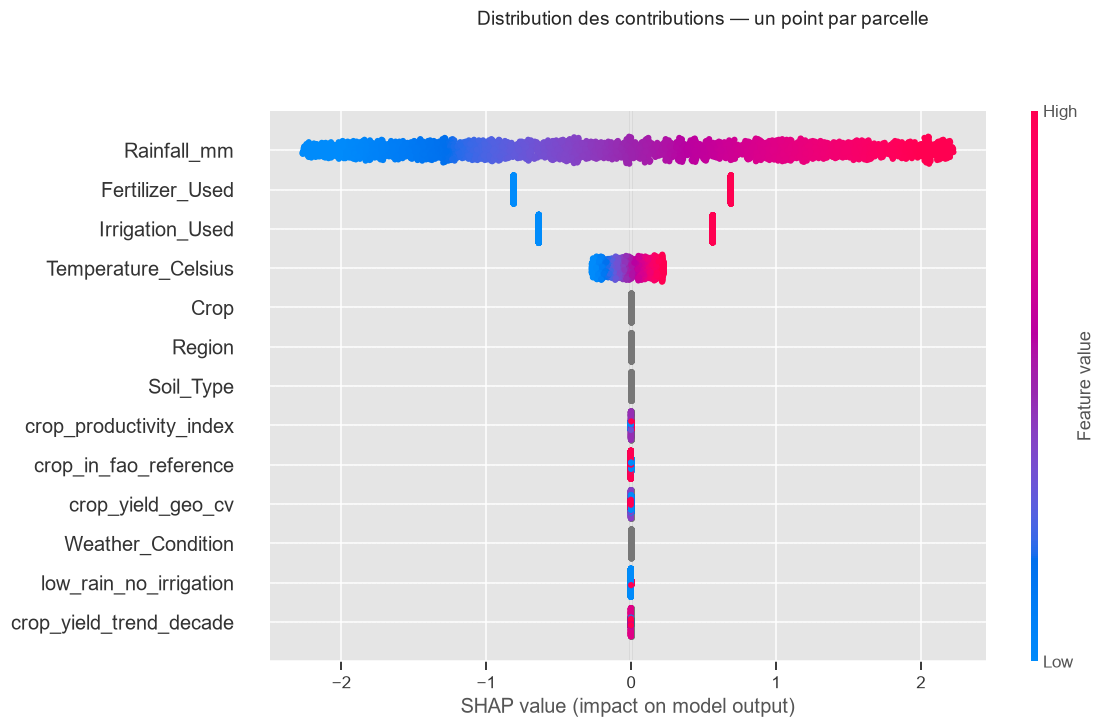

In [16]:
plt.figure()
shap.plots.beeswarm(couleur_ridge, max_display=len(FEATURES_MODELE), show=False)
figure = plt.gcf()
figure.set_size_inches(10.5, 6.5)
figure.suptitle('Distribution des contributions — un point par parcelle',
                fontsize=12.5, y=1.02)
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'shap_beeswarm.png'
figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

### 7.2 Dépendance locale — quatre parcelles

Un **waterfall** décompose **une prédiction** : de `E[f(X)]` au rendement prédit, variable par variable.

| Cas | Ce qu'il montre |
|---|---|
| rendement prédit le plus élevé | ce qui fait monter une prédiction |
| rendement prédit le plus faible | ce qui la fait descendre |
| parcelle médiane | le comportement typique |
| plus grande erreur | ce qui a construit **la prédiction** — non l'écart au réel, invisible au modèle |

écrit : shap_waterfall_1.png


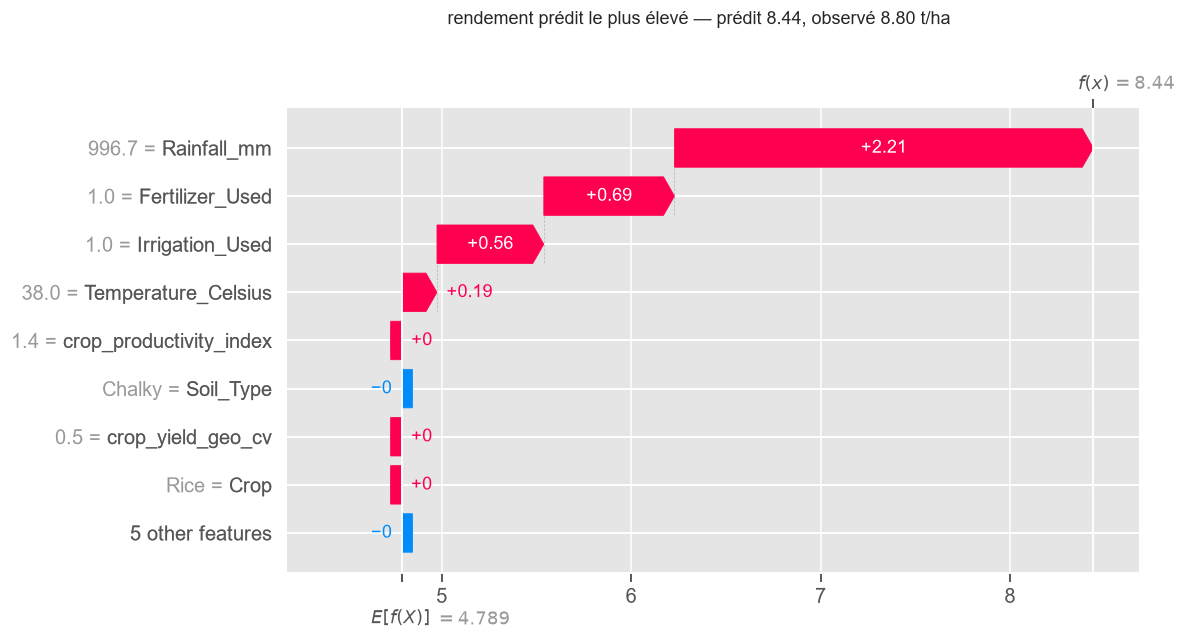

écrit : shap_waterfall_2.png


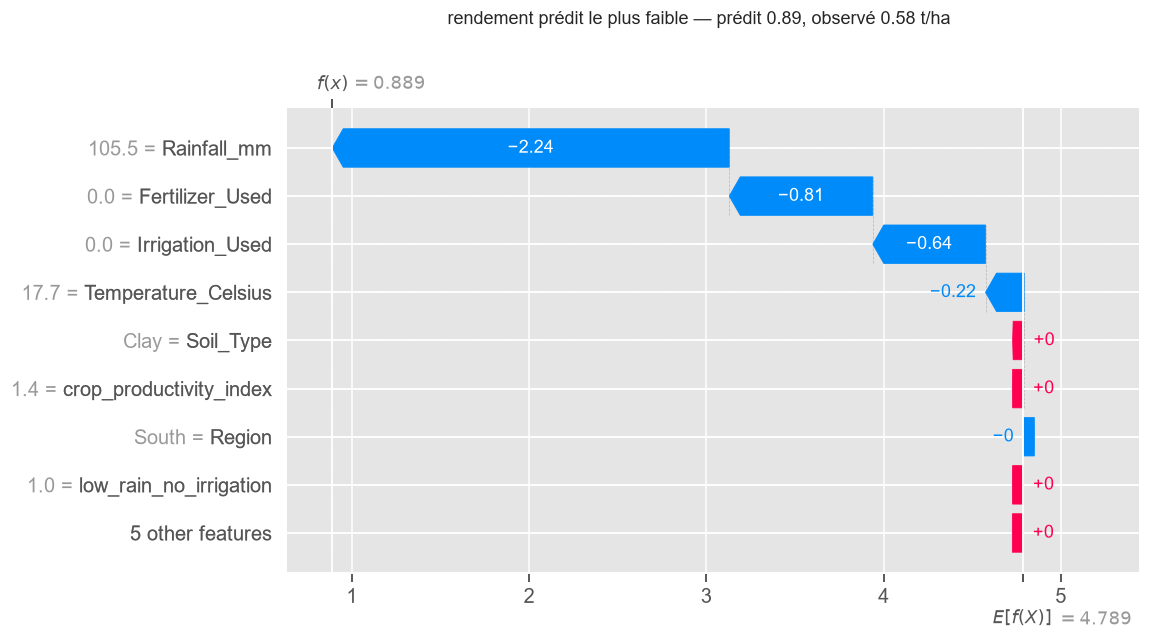

écrit : shap_waterfall_3.png


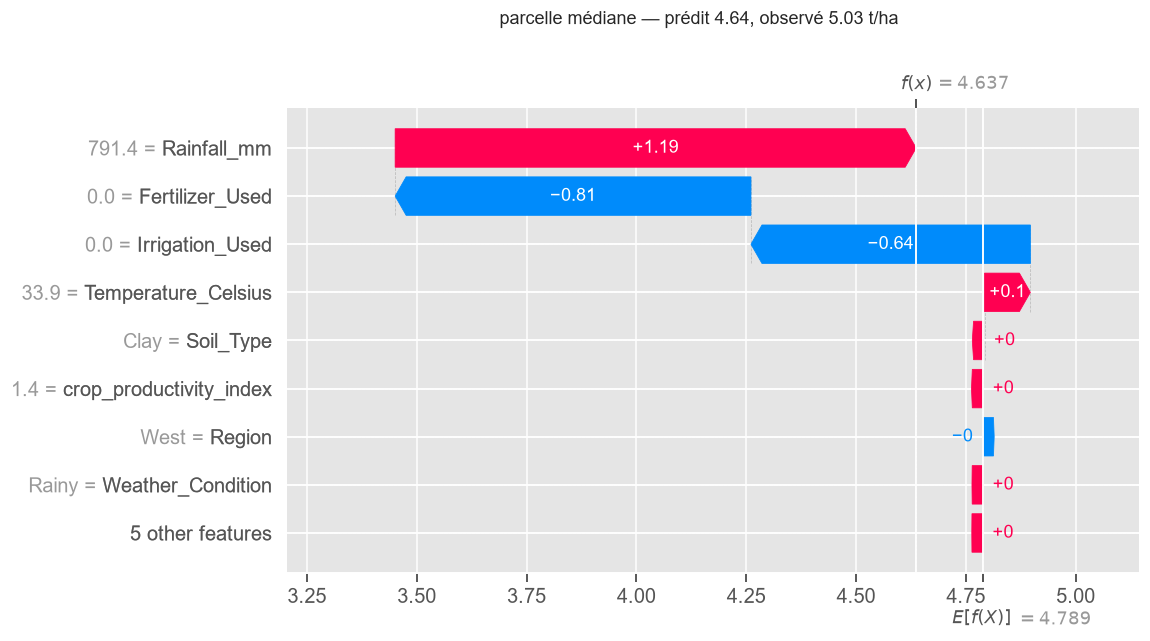

écrit : shap_waterfall_4.png


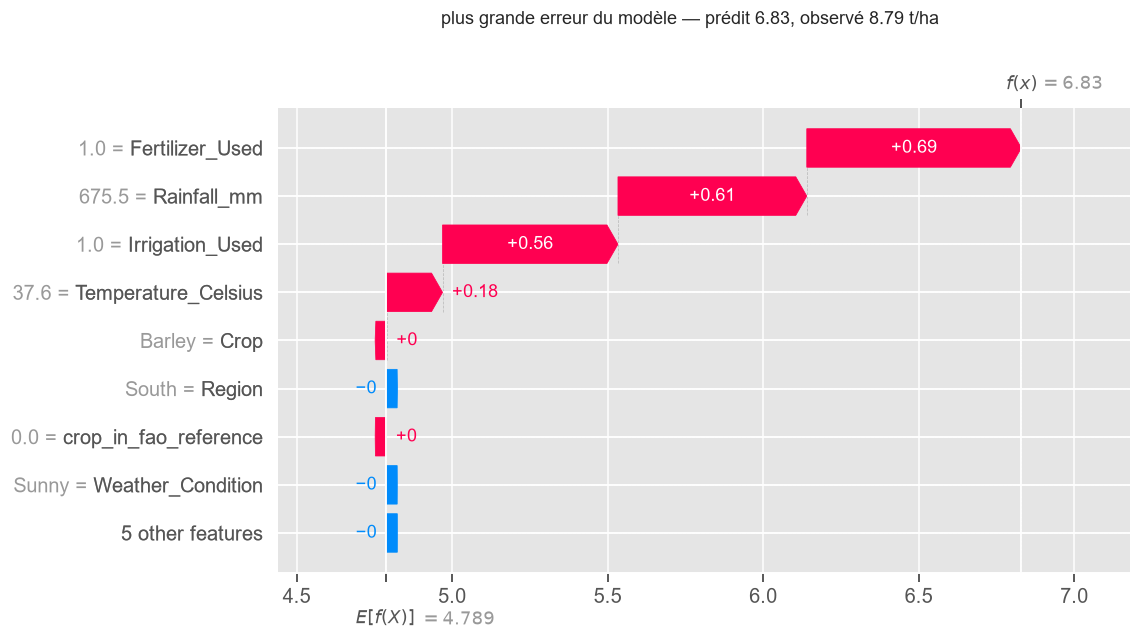

In [17]:
_, lecture_ridge = explications['ridge']
prediction_shap = modeles['ridge'].predict(X_shap)
observe_shap = val.loc[X_shap.index, TARGET].to_numpy()

# Quatre parcelles : deux extremes, une typique, un echec
CAS = {
    'rendement prédit le plus élevé': int(np.argmax(prediction_shap)),
    'rendement prédit le plus faible': int(np.argmin(prediction_shap)),
    'parcelle médiane': int(np.argsort(prediction_shap)[len(prediction_shap) // 2]),
    'plus grande erreur du modèle':
        int(np.argmax(np.abs(observe_shap - prediction_shap))),
}

# Une figure par cas : shap.plots.waterfall place ses etiquettes hors des axes
# et ne supporte pas d'etre place dans une grille de sous-graphiques.
for rang, (titre, i) in enumerate(CAS.items(), start=1):
    plt.figure()
    shap.plots.waterfall(lecture_ridge[i], max_display=9, show=False)
    figure = plt.gcf()
    figure.set_size_inches(10, 5.5)
    figure.suptitle(f'{titre} — prédit {prediction_shap[i]:.2f}, '
                    f'observé {observe_shap[i]:.2f} t/ha', fontsize=12, y=1.04)
    chemin = PROJECT_ROOT / 'reports' / 'figures' / f'shap_waterfall_{rang}.png'
    figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
    print('écrit :', chemin.name)
    plt.show()

### 7.3 Contre-épreuve : l'importance par permutation

Mesure **hors échantillon** et **modèle-agnostique**. Si elle s'accorde avec SHAP, la conclusion ne tient pas à la méthode.

In [18]:
# Importance par permutation : degradation du RMSE quand on melange une colonne.
# Hors echantillon, modele-agnostique, et insensible a l'encodage.
ECHANTILLON_PERM = 20_000
sous_ech = val.sample(ECHANTILLON_PERM, random_state=42)

permutation = {}
for nom in ['ridge', 'lightgbm']:
    debut = time.perf_counter()
    resultat = permutation_importance(
        modeles[nom], sous_ech[FEATURES_MODELE], sous_ech[TARGET],
        n_repeats=5, random_state=42, n_jobs=1,
        scoring='neg_root_mean_squared_error')
    permutation[nom] = pd.Series(resultat.importances_mean, index=FEATURES_MODELE)
    print(f'{nom:<10} {time.perf_counter() - debut:>5.1f} s')

perm_variables = pd.DataFrame(permutation).sort_values('ridge', ascending=False)
print('\nDégradation du RMSE quand la variable est mélangée (t/ha) :')
perm_variables.round(5)

ridge        1.2 s
lightgbm     4.3 s

Dégradation du RMSE quand la variable est mélangée (t/ha) :


,ridge,lightgbm
Rainfall_mm,1.39832,1.30819
Fertilizer_Used,0.67596,0.67539
Irrigation_Used,0.48623,0.38237
Temperature_Celsius,0.04133,0.04120
Region,0.00000,0.00001
Crop,0.00000,-0.00001
crop_productivity_index,0.00000,0.00000
crop_yield_geo_cv,0.00000,0.00000
low_rain_no_irrigation,0.00000,0.08306
crop_yield_trend_decade,0.00000,-0.00000


écrit : importance_variables.png


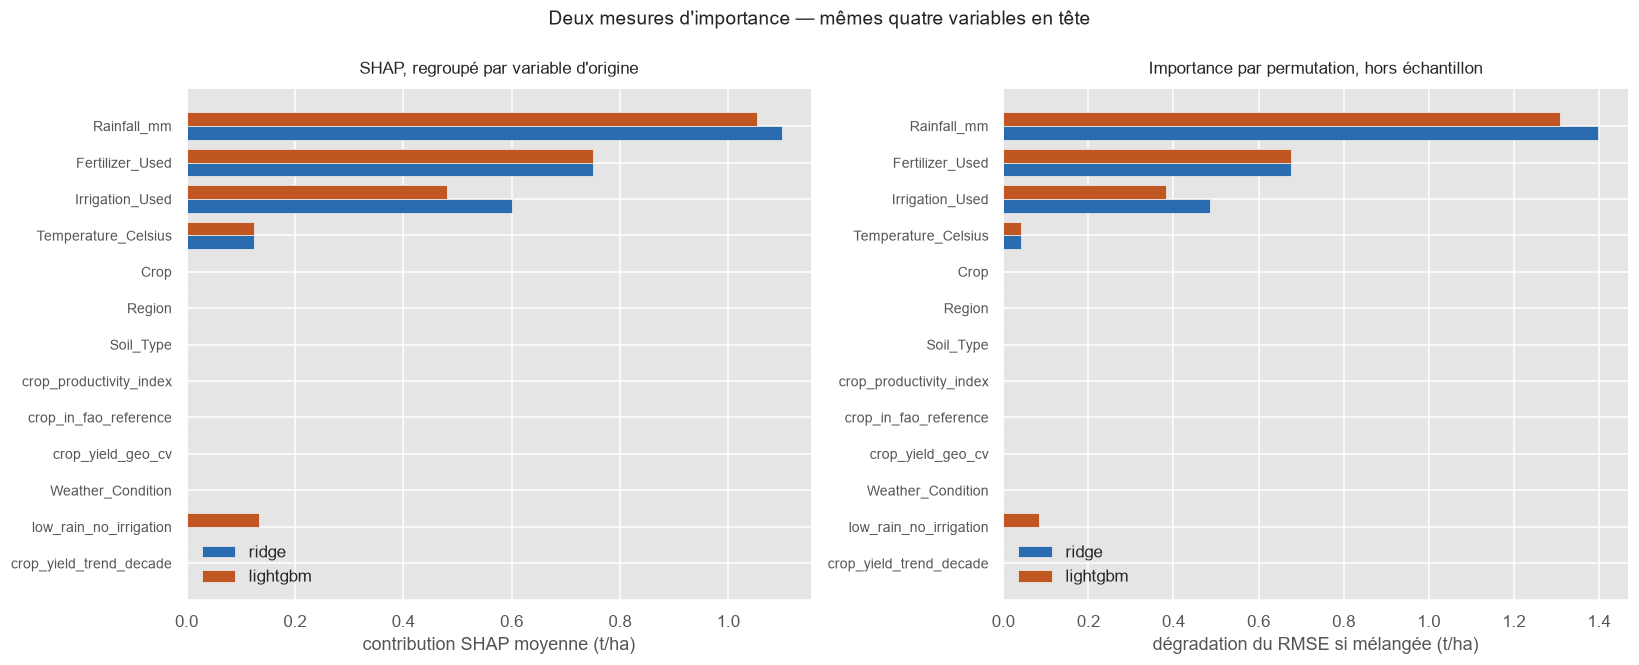

In [19]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(15, 6))

ordre = shap_variables.sort_values('ridge').index
position_y = np.arange(len(ordre))
largeur = 0.38
gauche.barh(position_y - largeur / 2, shap_variables.loc[ordre, 'ridge'],
            largeur, color=BLUE, label='ridge')
gauche.barh(position_y + largeur / 2, shap_variables.loc[ordre, 'lightgbm'],
            largeur, color=ORANGE, label='lightgbm')
gauche.set_yticks(position_y, ordre, fontsize=9)
gauche.set_xlabel('contribution SHAP moyenne (t/ha)')
gauche.set_title('SHAP, regroupé par variable d\'origine', fontsize=11, pad=10)
gauche.legend(frameon=False)

# Meme ordre de lignes a droite qu'a gauche : une ligne = une variable,
# sinon l'oeil compare des variables differentes d'un panneau a l'autre.
droite.barh(position_y - largeur / 2, perm_variables.loc[ordre, 'ridge'],
            largeur, color=BLUE, label='ridge')
droite.barh(position_y + largeur / 2, perm_variables.loc[ordre, 'lightgbm'],
            largeur, color=ORANGE, label='lightgbm')
droite.set_yticks(position_y, ordre, fontsize=9)
droite.set_xlabel('dégradation du RMSE si mélangée (t/ha)')
droite.set_title('Importance par permutation, hors échantillon',
                 fontsize=11, pad=10)
droite.legend(frameon=False)

for ax in (gauche, droite):
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)
fig.suptitle('Deux mesures d\'importance — mêmes quatre variables en tête',
             fontsize=12.5, y=1.0)
fig.tight_layout()
chemin = PROJECT_ROOT / 'reports' / 'figures' / 'importance_variables.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

In [20]:
# Demonstration du partage : cinq VARIABLES portent la meme information, la
# culture. Chacune recoit une part du credit, sans qu'aucune part ait de sens.
liees_culture = ['Crop'] + [c for c in FEATURES_MODELE if c.startswith('crop_')]
partage = shap_variables.loc[[c for c in liees_culture
                              if c in shap_variables.index]]
print('Contribution SHAP des cinq variables porteuses de la culture :')
print(partage.round(6).to_string())
print(f'\n  total ridge    : {partage["ridge"].sum():.6f} t/ha')
print(f'  total lightgbm : {partage["lightgbm"].sum():.6f} t/ha')
print()
print('  Ces cinq variables disent la meme chose : Crop determine les quatre')
print('  autres (eta = 1,00). Leur contribution individuelle n a donc aucun')
print('  sens agronomique — seule leur somme en a un.')

Contribution SHAP des cinq variables porteuses de la culture :
                            ridge  lightgbm
Crop                     0.001252  0.000972
crop_productivity_index  0.000638  0.000523
crop_yield_geo_cv        0.000355  0.000227
crop_yield_trend_decade  0.000032  0.000036
crop_in_fao_reference    0.000529  0.000173

  total ridge    : 0.002806 t/ha
  total lightgbm : 0.001931 t/ha

  Ces cinq variables disent la meme chose : Crop determine les quatre
  autres (eta = 1,00). Leur contribution individuelle n a donc aucun
  sens agronomique — seule leur somme en a un.


## 8. Ablation : ce que coûte le retrait de chaque variable

On réajuste sans la variable et on regarde ce qu'on perd. Seule mesure exempte de partage d'attribution, et seule à répondre à « faut-il la garder ? ».

In [21]:
from IPython.display import display

# Le modele de reference a ete optimise par Optuna. Reajuster les variantes avec
# un alpha arbitraire melangerait deux effets : le retrait de la variable ET le
# changement de regularisation. On reprend donc SON alpha.
ALPHA_REFERENCE = modeles['ridge'].named_steps['modele'].alpha
base = erreurs['ridge']
print(f'Reference : {len(FEATURES_MODELE)} variables, alpha {ALPHA_REFERENCE:.4f}, '
      f'RMSE {np.sqrt(base.mean()):.8f}\n')


def ablation(retirees, etiquette):
    """RMSE obtenu sans `retirees`, et significativite de l'ecart.

    Le z compare les erreurs quadratiques PARCELLE PAR PARCELLE : les deux
    modeles voient les memes lignes, l'appariement elimine la variabilite due
    a l'echantillon.
    """
    reste = [c for c in FEATURES_MODELE if c not in retirees]
    modele = training.construire_pipeline('ridge', {'alpha': ALPHA_REFERENCE}, reste)
    modele.fit(train[reste], train[TARGET])
    e = np.asarray((y_val - modele.predict(val[reste])) ** 2)
    d = e - base
    z = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    # z > 0 : retirer la variable DEGRADE le modele, donc elle servait.
    # z < 0 : le modele reduit fait marginalement mieux — ce qui est le
    # comportement attendu d'une variable sans signal, dont les colonnes
    # coutent de la variance d'estimation sans rien apporter en retour.
    return {'retire': etiquette, 'restantes': len(reste),
            'RMSE sans': np.sqrt(e.mean()), 'z': round(z, 1),
            'verdict': ('indispensable' if z > 10 else
                        'utile' if z > 2 else
                        'retrait neutre ou favorable' if z < -2 else
                        'sans apport detectable')}


individuelles = (pd.DataFrame([ablation([c], c) for c in FEATURES_MODELE])
                 .set_index('retire').sort_values('z', ascending=False))

# Puis par GROUPE : les quatre indicateurs FAO sont des fonctions de la culture,
# et portent donc la meme information que `Crop`. Retires un a un, chacun peut
# sembler inutile parce que les autres le remplacent ; seul le retrait du groupe
# entier dit ce que cette information apporte vraiment.
GROUPES = {
    'les 4 indicateurs FAO': list(FEATURES_FAO),
    'Crop seule': ['Crop'],
    'Crop ET les 4 FAO': ['Crop'] + list(FEATURES_FAO),
}
groupees = (pd.DataFrame([ablation(cols, nom) for nom, cols in GROUPES.items()])
            .set_index('retire'))

print('Variable par variable :')
display(individuelles.round(6))
print("\nPar groupe — l'information « culture » est portée par cinq colonnes :")
display(groupees.round(6))

Reference : 13 variables, alpha 17.0631, RMSE 0.50042586

Variable par variable :


,restantes,RMSE sans,z,verdict
retire,,,,
Fertilizer_Used,12,0.899937,288.6,indispensable
Rainfall_mm,12,1.174122,261.4,indispensable
Irrigation_Used,12,0.716146,182.5,indispensable
Temperature_Celsius,12,0.520258,54.1,indispensable
low_rain_no_irrigation,12,0.500427,1.3,sans apport detectable
crop_yield_trend_decade,12,0.500426,1.1,sans apport detectable
Weather_Condition,12,0.500427,0.8,sans apport detectable
Soil_Type,12,0.500424,-0.5,sans apport detectable
Region,12,0.500424,-0.6,sans apport detectable



Par groupe — l'information « culture » est portée par cinq colonnes :


,restantes,RMSE sans,z,verdict
retire,,,,
les 4 indicateurs FAO,9,0.500426,-2.8,retrait neutre ou favorable
Crop seule,12,0.500424,-0.9,sans apport detectable
Crop ET les 4 FAO,8,0.500413,-2.4,retrait neutre ou favorable


> **Lecture.** Quatre variables indispensables — `Fertilizer_Used`, `Rainfall_mm`, `Irrigation_Used`, `Temperature_Celsius` : en retirer une double au moins l'erreur. Les neuf autres ne laissent aucune trace.
>
> L'ablation **groupée** était nécessaire : une à une, les cinq colonnes de la culture pouvaient sembler inutiles parce que les autres la remplaçaient. Retirées **ensemble**, le masquage mutuel est écarté — le modèle à 8 variables fait aussi bien. Les z négatifs ne sont pas un gain (seuil à z ≈ 2,9 sur 16 tests, écart de 1,3·10⁻⁵ t/ha) mais une absence de signal.
>
> **Pour l'API** : `Crop` et les quatre FAO pourraient partir sans perte. On les garde parce que le protocole a été fixé avant la mesure — en changer après avoir vu `val` reviendrait à sélectionner sur le jeu qui sert à comparer.

## 9. La recommandation de culture est-elle possible ?

Seconde fonction demandée, indépendante du modèle retenu. À conditions de parcelle fixées, seule la culture varie : l'écart de rendement prédit mesure la matière disponible pour un conseil.

In [22]:
echantillon_culture = val.sample(20_000, random_state=42)
sensibilite = sensibilite_culture(modeles['ridge'], echantillon_culture,
                                  FEATURES_MODELE)

print('Rendement prédit moyen par culture, à conditions identiques :')
print(sensibilite['rendement_moyen_par_culture'].round(4).to_string())
print(f"\n  ecart moyen meilleure/pire : {sensibilite['ecart_moyen_t_ha']:.4f} t/ha")
print(f"  classement constant        : {sensibilite['classement_constant']}")
print(f"  culture en tete            : "
      f"{sensibilite['part_en_tete'].round(1).to_dict()}")

print('\nVerdict économique, sous plusieurs hypothèses de prix :')
mae = float(np.abs(y_val - predictions['ridge']).mean())
verdict = pd.DataFrame([
    {'prix_eur_t': prix,
     'erreur du modele (EUR/ha)': round(mae * prix, 1),
     'gain d un changement de culture (EUR/ha)':
         round(sensibilite['ecart_moyen_t_ha'] * prix, 2)}
    for prix in PRIX_SENSIBILITE]).set_index('prix_eur_t')
verdict['rapport'] = (verdict.iloc[:, 0] / verdict.iloc[:, 1]).round(0)
verdict

Rendement prédit moyen par culture, à conditions identiques :
Barley     4.6483
Rice       4.6475
Cotton     4.6450
Soybean    4.6446
Maize      4.6444
Wheat      4.6418

  ecart moyen meilleure/pire : 0.0065 t/ha
  classement constant        : True
  culture en tete            : {'Barley': 100.0}

Verdict économique, sous plusieurs hypothèses de prix :


,erreur du modele (EUR/ha),gain d un changement de culture (EUR/ha),rapport
prix_eur_t,,,
150,59.9,0.97,62.0
200,79.9,1.29,62.0
300,119.8,1.94,62.0


## 10. Contraintes de déploiement

In [23]:
deploiement = []
for nom in MODELES:
    chemin = training.chemin_modele(nom, 'modele')
    latences = latence_prediction(modeles[nom], val, FEATURES_MODELE)
    deploiement.append({
        'modele': nom,
        'latence unitaire (ms)': round(latences['latence_unitaire_ms'], 2),
        'latence lot (ms)': round(latences['latence_lot_ms'], 1),
        'taille (Ko)': round(chemin.stat().st_size / 1024, 1),
        'interpretable': 'coefficients' if nom in ('ridge', 'dummy') else 'SHAP seulement',
    })
pd.DataFrame(deploiement).set_index('modele')

,latence unitaire (ms),latence lot (ms),taille (Ko),interpretable
modele,,,,
dummy,3.01,3.7,5.0,coefficients
ridge,2.99,3.2,5.4,coefficients
histgbm,10.49,12.8,602.1,SHAP seulement
lightgbm,6.61,9.4,1280.0,SHAP seulement


## 11. Décision

> **Tout ce qui précède repose sur `val`. Le choix du modèle est arrêté ici, et ne sera pas révisé après l'ouverture de `test`.**

In [24]:
criteres = pd.DataFrame([
    {'critere': 'RMSE sur validation',
     'gagnant': comparaison.index[0],
     'detail': f"{comparaison.iloc[0]['rmse']:.6f} contre "
               f"{comparaison.iloc[1]['rmse']:.6f}"},
    {'critere': 'ecart statistiquement reel ?',
     'gagnant': comparaison.index[0],
     'detail': f"z = {test_apparie(comparaison.index[0], comparaison.index[1]):.1f} "
               f"contre {comparaison.index[1]}"},
    {'critere': 'stabilite entre cultures',
     'gagnant': 'non departage',
     'detail': 'intervalles recouvrants : aucune difference mise en evidence'},
    {'critere': 'latence unitaire',
     'gagnant': min((d for d in deploiement if d['modele'] != 'dummy'),
                    key=lambda d: d['latence unitaire (ms)'])['modele'],
     'detail': ' | '.join(f"{d['modele']} {d['latence unitaire (ms)']} ms"
                          for d in deploiement if d['modele'] != 'dummy')},
    {'critere': 'taille de l artefact',
     'gagnant': min((d for d in deploiement if d['modele'] != 'dummy'),
                    key=lambda d: d['taille (Ko)'])['modele'],
     'detail': ' | '.join(f"{d['modele']} {d['taille (Ko)']:.0f} Ko"
                          for d in deploiement if d['modele'] != 'dummy')},
    {'critere': 'interpretabilite',
     'gagnant': 'ridge',
     'detail': 'coefficients lisibles ; les GBM exigent SHAP'},
]).set_index('critere')
criteres

,gagnant,detail
critere,,
RMSE sur validation,ridge,0.500426 contre 0.500795
ecart statistiquement reel ?,ridge,z = 7.6 contre lightgbm
stabilite entre cultures,non departage,intervalles recouvrants : aucune difference mi...
latence unitaire,ridge,ridge 2.99 ms | histgbm 10.49 ms | lightgbm 6....
taille de l artefact,ridge,ridge 5 Ko | histgbm 602 Ko | lightgbm 1280 Ko
interpretabilite,ridge,coefficients lisibles ; les GBM exigent SHAP


### Le modèle retenu

**Ridge**, gagnant sur chaque critère mesuré : RMSE (écart réel), latence, taille d'artefact, et seul dont les coefficients se lisent directement.

Réserve à porter au rapport : **son avance sur LightGBM, bien que réelle, est pratiquement nulle** — quelques centièmes d'euro par hectare. Ce qui tranche, c'est qu'il ne perd sur aucun autre axe.

Les quatre variables porteuses de signal sont celles de la fonction génératrice reconstituée à l'étape 1.

---

## 12. Ouverture du jeu de test

> **La décision est prise. `test` n'intervient plus dans aucun choix.**
>
> Ces 149 966 parcelles n'ont jamais été lues : elles ne donnent une estimation **non biaisée** que parce qu'aucune décision n'a été prise en les regardant.

---

In [25]:
# Premiere et unique lecture de test dans tout le projet
_, _, test = training.charger_partitions(avec_test=True)
X_test, y_test = test[FEATURES_MODELE], test[TARGET]

MODELE_RETENU = 'ridge'

# Le choix de la section 11 est humain et multicritere, pas un argmin : il
# pourrait legitimement retenir un modele qui n'est pas le meilleur en RMSE.
# Mais il ne doit pas contredire SILENCIEUSEMENT le tableau de criteres.
# `comparaison` est triee par RMSE croissant : si la tete change, cette
# assertion arrete le notebook avant toute evaluation sur test.
assert MODELE_RETENU == comparaison.index[0], (
    f'{MODELE_RETENU} est retenu, mais {comparaison.index[0]} a le meilleur '
    'RMSE sur val. Reprendre la section 11 avant de continuer.')

modele_final = modeles[MODELE_RETENU]
prediction_test = modele_final.predict(X_test)

final = pd.DataFrame([
    {'jeu': 'validation (a servi au choix)',
     **metriques_prediction(y_val, predictions[MODELE_RETENU]),
     **metriques_economiques(y_val, predictions[MODELE_RETENU])},
    {'jeu': 'TEST (jamais vu)',
     **metriques_prediction(y_test, prediction_test),
     **metriques_economiques(y_test, prediction_test)},
]).set_index('jeu')

print(f'Modele retenu : {MODELE_RETENU} | test = {len(test):,} parcelles\n')
final.round(4)

Modele retenu : ridge | test = 149,966 parcelles



,rmse,mae,r2,mae_eur_ha,cout_asymetrique_eur_ha,biais_eur_ha
jeu,,,,,,
validation (a servi au choix),0.5004,0.3993,0.9132,79.8690,99.9171,0.3234
TEST (jamais vu),0.5013,0.3998,0.9121,79.9649,99.8779,-0.3125


In [26]:
# Les runs d'optimisation ne portent que des metriques de `val`. L'evaluation
# finale part donc dans un run SEPARE, marque `phase=test` : melangees dans un
# meme tri par RMSE, les deux phases ne voudraient plus rien dire.
#
# La fonction est idempotente — relancer ce notebook met a jour le run au lieu
# d'en creer un second.
run_test = training.journaliser_evaluation_test(
    MODELE_RETENU, modele_final, FEATURES_MODELE, val, test)

c:\Users\faiza\Formation_IA\Projet12_mission\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
c:\Users\faiza\Formation_IA\Projet12_mission\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


  run « evaluation-finale-ridge » cree
  val_rmse 0.5004  ->  test_rmse 0.5013   (ecart +0.0008)


**Trace dans MLflow.** `val` et `test` sont enregistrés côte à côte dans un run `evaluation-finale-ridge`, avec leur écart (`ecart_val_test_rmse`). C'est cet écart qui démontre l'absence de surapprentissage : une valeur de test seule n'aurait aucun point de comparaison.

## 13. Lecture métier

Les coefficients d'un modèle linéaire se lisent en unités réelles. **Réserve** : les quatre variables FAO étant déterminées par `Crop`, leurs coefficients se partagent arbitrairement l'effet culture.

In [27]:
noms_colonnes = modele_final[:-1].get_feature_names_out()
coefficients = pd.Series(modele_final[-1].coef_, index=noms_colonnes)

# Le scaler ne connait pas les noms de colonnes : l'imputeur en amont lui
# passe un tableau. On les reprend dans la specification du ColumnTransformer.
pretraitement = modele_final.named_steps['pretraitement']
colonnes_quanti = next(cols for nom, _, cols in pretraitement.transformers_
                       if nom == 'quantitatives')
echelle = pretraitement.named_transformers_['quantitatives'] \
    .named_steps['standardscaler']

# Les quantitatives sont standardisees : on ramene le coefficient a l'unite
# d'origine, pour qu'il se lise en t/ha par mm, par degre, etc.
reels = coefficients.copy()
for colonne, ecart_type in zip(colonnes_quanti, echelle.scale_):
    reels[colonne] = coefficients[colonne] / ecart_type

# Un coefficient est par nature une grandeur PAR COLONNE : c'est ainsi qu'un
# modele lineaire est construit. On le rapproche de la contribution de sa
# variable d'origine, deja regroupee en section 7.
lecture = pd.DataFrame({
    'coefficient (unite reelle)': reels.round(6),
    'variable d origine': [variable_source(c) for c in reels.index],
})
lecture['SHAP de la variable'] = (shap_variables['ridge']
                                  .reindex(lecture['variable d origine'])
                                  .to_numpy())
lecture = lecture.sort_values('SHAP de la variable', ascending=False)
print('Effet de chaque colonne, rapproche de la contribution de sa variable :')
lecture.head(12)

Effet de chaque colonne, rapproche de la contribution de sa variable :


,coefficient (unite reelle),variable d origine,SHAP de la variable
Rainfall_mm,0.004996,Rainfall_mm,1.098189
Fertilizer_Used,1.499967,Fertilizer_Used,0.750064
Irrigation_Used,1.200138,Irrigation_Used,0.600669
Temperature_Celsius,0.019912,Temperature_Celsius,0.125427
Crop_Cotton,-0.001024,Crop,0.001252
Crop_Maize,0.000438,Crop,0.001252
Crop_Wheat,-0.002657,Crop,0.001252
Crop_Soybean,0.000596,Crop,0.001252
Crop_Rice,0.000411,Crop,0.001252
Crop_Barley,0.002236,Crop,0.001252


In [28]:
print('Sensibilité au prix — la conclusion dépend-elle de l hypothèse ?\n')
sensibilite_au_prix(y_test, prediction_test, PRIX_SENSIBILITE).round(2)

Sensibilité au prix — la conclusion dépend-elle de l hypothèse ?



,mae_eur_ha,cout_asymetrique_eur_ha,biais_eur_ha
prix_eur_t,,,
150,59.97,74.91,-0.23
200,79.96,99.88,-0.31
300,119.95,149.82,-0.47


## 14. Export du modèle retenu

In [29]:
training.exporter_joblib(modele_final, FINAL_MODEL_PATH)

# Relecture dans un etat neuf : l'artefact est-il autonome ?
recharge = joblib.load(FINAL_MODEL_PATH)
identique = np.allclose(recharge.predict(X_test.head(100)), prediction_test[:100])
print(f'Relecture et prédiction identiques : {identique}')
print(f"\nversions attachees : data {versions['data_version']} | "
      f"split {versions['split_version']}")

  modele_final.joblib             0.01 Mo
Relecture et prédiction identiques : True

versions attachees : data c9547cbd218b | split ccb2a631078f


In [30]:
# Le .joblib ci-dessus est le livrable demande par la mission. Le registre
# MLflow, lui, est ce vers quoi pointera l'API : `train.py` y a publie une
# version par modele entraine, aucune n'etant privilegiee. C'est ici, et
# seulement ici, que le choix de la section 11 devient effectif.
version_champion = training.promouvoir_champion(MODELE_RETENU)

  agritech-rendement version 2 (ridge) -> alias « champion »
  l'API chargera : models:/agritech-rendement@champion


**Deux sorties, deux usages.** `modele_final.joblib` est le fichier livré avec le projet. Le registre MLflow est le point d'entrée de l'API : elle chargera `models:/agritech-rendement@champion` sans rien savoir du modèle qu'il désigne. Changer de modèle en production reviendra à déplacer cet alias — pas à redéployer l'API.

## À retenir

- **Ridge est retenu** : meilleur RMSE (écart réel), latence et artefact les plus faibles, coefficients lisibles. Son avance prédictive est pourtant **pratiquement nulle** — c'est l'absence de défaut qui le désigne. Sur `test` : RMSE 0,5013, R² 0,912.
- **Quatre variables portent tout le signal** : pluviométrie, température, fertilisation, irrigation. Ablation, SHAP et permutation concordent ; les neuf autres n'apportent rien de détectable.
- **La recommandation de culture est impossible** : 0,0065 t/ha d'écart entre meilleure et pire culture, soit 1,29 €/ha contre 79,9 €/ha d'erreur — et un classement constant, qui ne dépend donc pas des conditions.
- **Portée** : les variables climatiques décrivent une saison **observée**. L'application simule un rendement sous conditions renseignées ; elle ne prévoit pas avant semis.